# 01 - Análisis exploratorio (EDA) del catálogo de Siman GT

Entrada: `data/processed/catalogo.csv` (salida de `src/data/limpieza.py`). Las gráficas se guardan en `reports/figuras/` como `eda_<tema>.png`.
La parte de H&M se agrega después.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

os.makedirs("../reports/figuras", exist_ok=True)
df = pd.read_csv("../data/processed/catalogo.csv", dtype={"product_id": str, "item_id": str})

# Estilo: superficie clara, tinta en grises, un solo color de serie (azul)
SUPERFICIE, TINTA, TINTA2, MUDO = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, EJE, AZUL, GRIS = "#e1e0d9", "#c3c2b7", "#2a78d6", "#a8a79f"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "text.color": TINTA,
    "xtick.color": MUDO, "ytick.color": MUDO, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlepad": 12,
    "font.size": 10, "figure.dpi": 100,
})
miles = lambda x, _: f"{x:,.0f}"  # separador de miles en los ejes

## 1. Resumen inicial

In [2]:
print(f"Filas: {len(df):,}")
print(f"Productos únicos (product_id): {df['product_id'].nunique():,}")
print(f"Items únicos (item_id): {df['item_id'].nunique():,}")
print(f"Marcas únicas: {df['marca'].nunique():,}")

pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
    "tipo": df.dtypes.astype(str),
})

Filas: 11,786
Productos únicos (product_id): 10,947
Items únicos (item_id): 11,786
Marcas únicas: 215


,nulos,% nulos,valores únicos,tipo
product_id,0,0.0,10947,str
item_id,0,0.0,11786,str
nombre,0,0.0,9115,str
marca,0,0.0,215,str
categoria,0,0.0,178,str
color,0,0.0,40,str
descripcion,0,0.0,8655,str
precio_q,0,0.0,403,float64
precio_lista_q,0,0.0,194,float64
disponible,0,0.0,2,bool


**Hallazgo:** 11,786 filas, 10,947 productos únicos y 215 marcas, sin nulos en ninguna de las 17 columnas. Las 839 filas de diferencia entre `item_id` y `product_id` son colores distintos del mismo producto.

## 2. Prendas por sección

         prendas     %
seccion               
mujer       5493  46.6
hombre      3132  26.6
bebe        1130   9.6
nina         988   8.4
nino         912   7.7
unisex       131   1.1


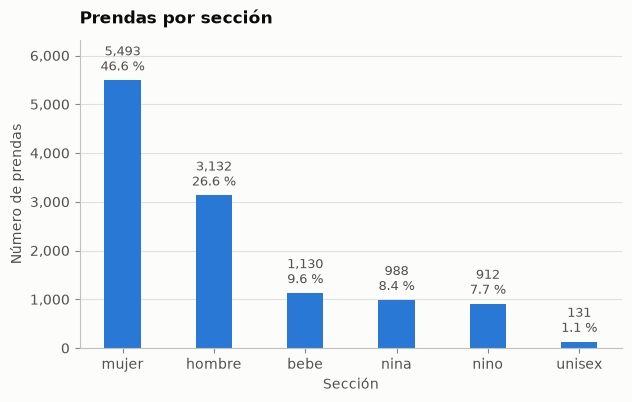

In [3]:
por_seccion = df["seccion"].value_counts()
pct_seccion = por_seccion / len(df) * 100
print(pd.DataFrame({"prendas": por_seccion, "%": pct_seccion.round(1)}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(por_seccion.index, por_seccion.values, width=0.4, color=AZUL)
ax.bar_label(barras, labels=[f"{n:,}\n{p:.1f} %" for n, p in zip(por_seccion, pct_seccion)],
             padding=4, color=TINTA2, fontsize=9)
ax.set_title("Prendas por sección")
ax.set_xlabel("Sección")
ax.set_ylabel("Número de prendas")
ax.set_ylim(0, por_seccion.max() * 1.15)
ax.yaxis.set_major_formatter(miles)
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_seccion.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** mujer (5,493; 46.6 %) y hombre (3,132; 26.6 %) suman el 73.2 % del catálogo; unisex tiene solo 131 prendas (1.1 %) y bebé, niña y niño tienen entre 912 y 1,130 cada una.

## 3. Top 20 de `tipo_prenda`

Tipos de prenda: 55
El top 20 cubre 83.9% del catálogo
Tipos con menos de 30 prendas: 13 (170 prendas, 1.4% del catálogo)
{'accesorio cabello': 28, 'ropa interior': 23, 'sudadera': 23, 'sombrilla': 22, 'faja': 19, 'bufanda': 12, 'bota': 12, 'pantufla': 12, 'panuelo': 8, 'top': 5, 'babydoll': 3, 'abrigo': 2, 'complemento formal': 1}


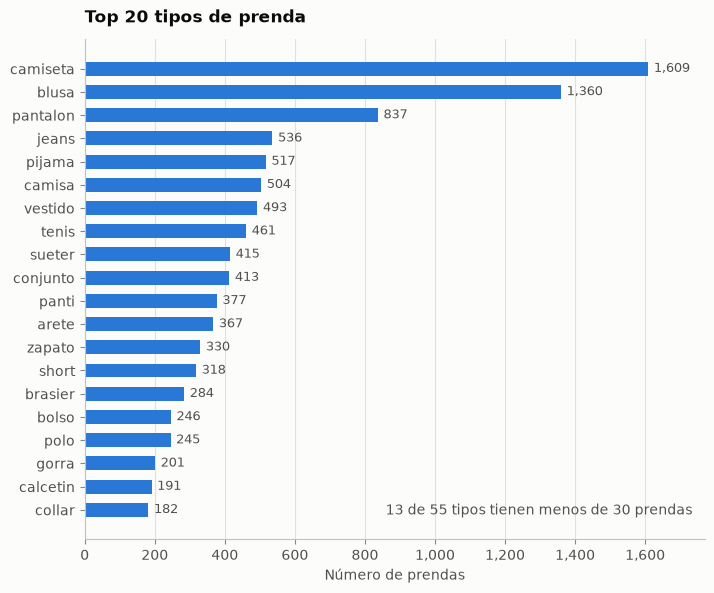

In [4]:
por_tipo = df["tipo_prenda"].value_counts()
raros = por_tipo[por_tipo < 30]
print(f"Tipos de prenda: {len(por_tipo)}")
print(f"El top 20 cubre {por_tipo.head(20).sum() / len(df):.1%} del catálogo")
print(f"Tipos con menos de 30 prendas: {len(raros)} ({raros.sum()} prendas, {raros.sum() / len(df):.1%} del catálogo)")
print(raros.to_dict())

top20 = por_tipo.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
barras = ax.barh(top20.index, top20.values, height=0.6, color=AZUL)
ax.bar_label(barras, labels=[f"{n:,}" for n in top20.values], padding=4, color=TINTA2, fontsize=9)
ax.text(0.98, 0.05, f"{len(raros)} de {len(por_tipo)} tipos tienen menos de 30 prendas",
        transform=ax.transAxes, ha="right", color=TINTA2)
ax.set_title("Top 20 tipos de prenda")
ax.set_xlabel("Número de prendas")
ax.set_xlim(0, top20.max() * 1.1)
ax.xaxis.set_major_formatter(miles)
ax.grid(axis="x")
plt.savefig("../reports/figuras/eda_tipo_prenda.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** cola larga: el top 20 cubre el 83.9 % del catálogo y camiseta (1,609) y blusa (1,360) dominan. 13 de 55 tipos tienen menos de 30 prendas (170 en total, 1.4 %), por ejemplo sudadera (23), bota (12) y abrigo (2).

## 4. Distribución de `color_base`

color_base    azul   negro  blanco  multicolor  beige  metalico  verde   cafe  rosado   gris   otro   rojo  naranja  morado  amarillo
prendas     2116.0  1544.0  1487.0      1294.0  938.0     789.0  704.0  617.0   599.0  441.0  437.0  418.0    151.0   147.0     104.0
%             18.0    13.1    12.6        11.0    8.0       6.7    6.0    5.2     5.1    3.7    3.7    3.5      1.3     1.2       0.9
multicolor + metalico + otro: 2,520 prendas (21.4%)


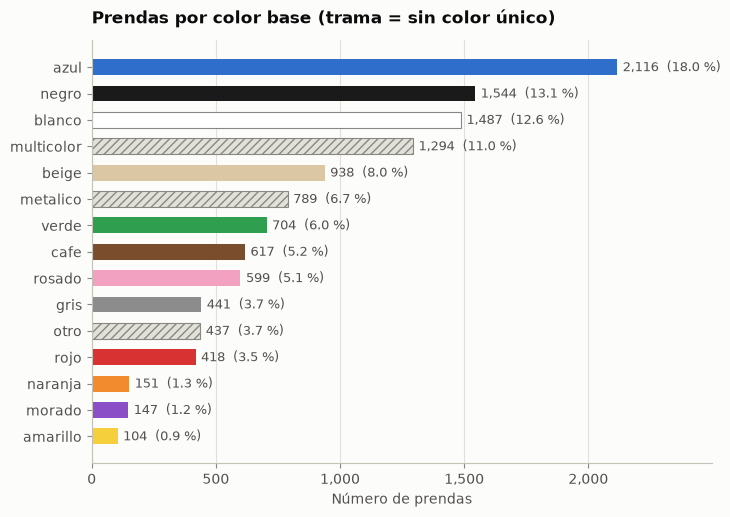

In [5]:
# Cada barra lleva su color real. Multicolor, metálico y otro no son un color único: gris claro con trama.
colores_reales = {
    "negro": "#1a1a1a", "blanco": "#ffffff", "gris": "#8c8c8c", "azul": "#2f6fcb", "rojo": "#d93232",
    "rosado": "#f2a1c0", "verde": "#2f9e4f", "amarillo": "#f5d03c", "naranja": "#f28a2e",
    "morado": "#8a4fc7", "cafe": "#7a4e2d", "beige": "#dcc7a4",
}
por_color = df["color_base"].value_counts()
pct_color = por_color / len(df) * 100
print(pd.DataFrame({"prendas": por_color, "%": pct_color.round(1)}).T.to_string())
sin_color = por_color[~por_color.index.isin(colores_reales)]
print(f"multicolor + metalico + otro: {sin_color.sum():,} prendas ({sin_color.sum() / len(df):.1%})")

orden = por_color[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
barras = ax.barh(orden.index, orden.values, height=0.6, linewidth=0.8,
                 color=[colores_reales.get(c, GRID) for c in orden.index])
for barra, c in zip(barras, orden.index):
    if c not in colores_reales:
        barra.set_hatch("////")
    if c not in colores_reales or c == "blanco":
        barra.set_edgecolor(MUDO)  # borde solo donde el relleno se confunde con el fondo
ax.bar_label(barras, labels=[f"{n:,}  ({p:.1f} %)" for n, p in zip(orden.values, pct_color[::-1])],
             padding=4, color=TINTA2, fontsize=9)
ax.set_title("Prendas por color base (trama = sin color único)")
ax.set_xlabel("Número de prendas")
ax.set_xlim(0, orden.max() * 1.18)
ax.xaxis.set_major_formatter(miles)
ax.grid(axis="x")
plt.savefig("../reports/figuras/eda_color_base.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** azul (18.0 %), negro (13.1 %) y blanco (12.6 %) concentran el 43.7 % del catálogo. Multicolor, metálico y otro suman 2,520 prendas (21.4 %) que no tienen un color base único.

## 5. Precio en quetzales

Q mín 17 | P10 79 | mediana 219 | P90 503 | P99 1300 | máx 3449 | media 276
          count    10%    50%    90%
seccion                             
bebe     1130.0   83.0  162.0  249.0
hombre   3132.0  127.0  279.0  679.0
mujer    5493.0   84.0  239.0  529.0
nina      988.0   59.0  127.0  247.0
nino      912.0   79.0  159.0  299.0
unisex    131.0  113.0  239.0  379.0


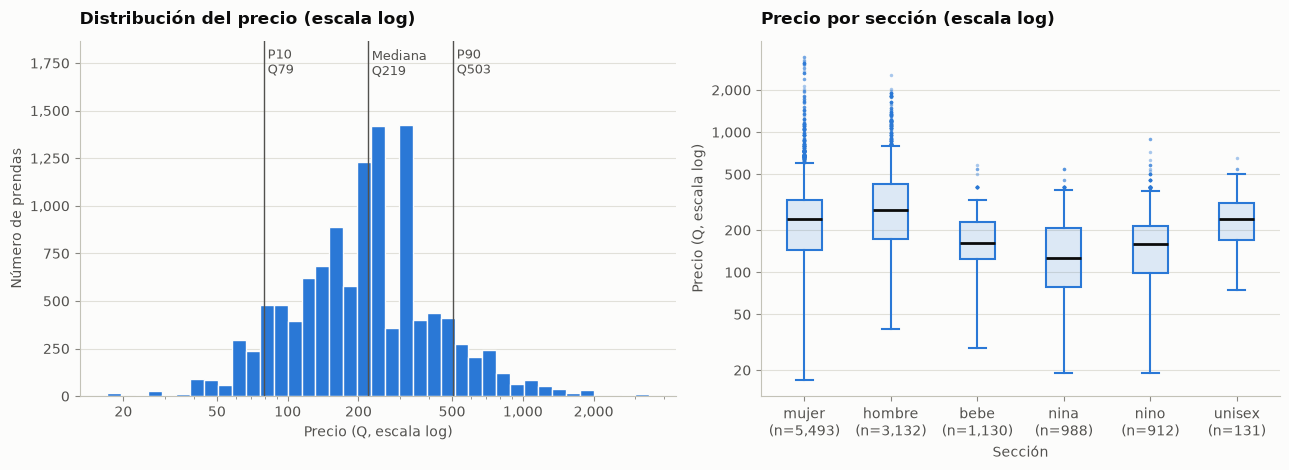

In [6]:
p10, mediana, p90 = df["precio_q"].quantile([0.10, 0.50, 0.90])
print(f"Q mín {df['precio_q'].min():.0f} | P10 {p10:.0f} | mediana {mediana:.0f} | P90 {p90:.0f} | "
      f"P99 {df['precio_q'].quantile(0.99):.0f} | máx {df['precio_q'].max():.0f} | media {df['precio_q'].mean():.0f}")
print(df.groupby("seccion")["precio_q"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%"]].round(0))

orden_secc = list(por_seccion.index)
ticks = [20, 50, 100, 200, 500, 1000, 2000]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})

# Histograma con escala log (el precio tiene cola larga a la derecha)
bins = np.logspace(np.log10(df["precio_q"].min()), np.log10(df["precio_q"].max()), 40)
ax1.hist(df["precio_q"], bins=bins, color=AZUL, edgecolor=SUPERFICIE, linewidth=1)
ax1.set_xscale("log")
ax1.set_xticks(ticks)
ax1.xaxis.set_major_formatter(miles)
ax1.yaxis.set_major_formatter(miles)
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.25)  # aire arriba para las etiquetas
for valor, nombre in [(p10, "P10"), (mediana, "Mediana"), (p90, "P90")]:
    ax1.axvline(valor, color=TINTA2, linewidth=1)
    ax1.text(valor * 1.04, ax1.get_ylim()[1] * 0.98, f"{nombre}\nQ{valor:.0f}", color=TINTA2, fontsize=9, va="top")
ax1.set_title("Distribución del precio (escala log)")
ax1.set_xlabel("Precio (Q, escala log)")
ax1.set_ylabel("Número de prendas")
ax1.grid(axis="y")

# Boxplot por sección
ax2.boxplot([df.loc[df["seccion"] == s, "precio_q"] for s in orden_secc],
            tick_labels=[f"{s}\n(n={por_seccion[s]:,})" for s in orden_secc],
            patch_artist=True, widths=0.4,
            boxprops={"facecolor": AZUL + "26", "edgecolor": AZUL, "linewidth": 1.5},
            medianprops={"color": TINTA, "linewidth": 2},
            whiskerprops={"color": AZUL, "linewidth": 1.5}, capprops={"color": AZUL, "linewidth": 1.5},
            flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": AZUL + "66", "markeredgecolor": "none"})
ax2.set_yscale("log")
ax2.set_yticks(ticks)
ax2.yaxis.set_major_formatter(miles)
ax2.minorticks_off()
ax2.set_title("Precio por sección (escala log)")
ax2.set_xlabel("Sección")
ax2.set_ylabel("Precio (Q, escala log)")
ax2.grid(axis="y")

plt.tight_layout()
plt.savefig("../reports/figuras/eda_precio.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** el precio tiene cola larga a la derecha: mediana Q219, P10 Q79 y P90 Q503 (media Q276, máximo Q3,449). La mediana por sección va de Q127 en niña y Q159 en niño hasta Q239 en mujer y Q279 en hombre.

## 6. Top 15 marcas y concentración

Marcas: 215 | top 1 (Sfera): 15.7% | top 10: 43.1% | top 15: 52.1%
Marcas con menos de 10 prendas: 85 | con 1 sola prenda: 19


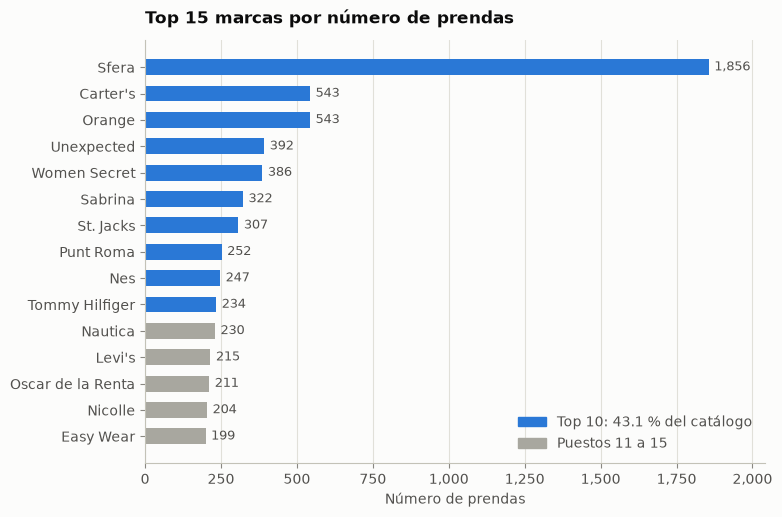

In [7]:
por_marca = df["marca"].value_counts()
pct_top10 = por_marca.head(10).sum() / len(df) * 100
print(f"Marcas: {len(por_marca)} | top 1 ({por_marca.index[0]}): {por_marca.iloc[0] / len(df):.1%} | "
      f"top 10: {pct_top10:.1f}% | top 15: {por_marca.head(15).sum() / len(df):.1%}")
print(f"Marcas con menos de 10 prendas: {(por_marca < 10).sum()} | con 1 sola prenda: {(por_marca == 1).sum()}")

top15 = por_marca.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
barras = ax.barh(top15.index, top15.values, height=0.6, color=[GRIS] * 5 + [AZUL] * 10)
ax.bar_label(barras, labels=[f"{n:,}" for n in top15.values], padding=4, color=TINTA2, fontsize=9)
ax.legend(handles=[Patch(color=AZUL, label=f"Top 10: {pct_top10:.1f} % del catálogo"),
                   Patch(color=GRIS, label="Puestos 11 a 15")],
          loc="lower right", frameon=False, labelcolor=TINTA2)
ax.set_title("Top 15 marcas por número de prendas")
ax.set_xlabel("Número de prendas")
ax.set_xlim(0, top15.max() * 1.1)
ax.xaxis.set_major_formatter(miles)
ax.grid(axis="x")
plt.savefig("../reports/figuras/eda_marcas.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** Sfera sola es el 15.7 % del catálogo (1,856 prendas) y las 10 marcas principales cubren el 43.1 %. En la cola, 85 de las 215 marcas tienen menos de 10 prendas y 19 tienen una sola.

## 7. Descuentos

Prendas con descuento: 3,413 (29.0%)
{'count': 3413.0, 'mean': 31.4, 'std': 13.8, 'min': 10.0, '25%': 20.0, '50%': 30.1, '75%': 40.2, 'max': 81.8}
Descuento más frecuente: 20 % (1,462 prendas, 42.8% de las que tienen descuento)


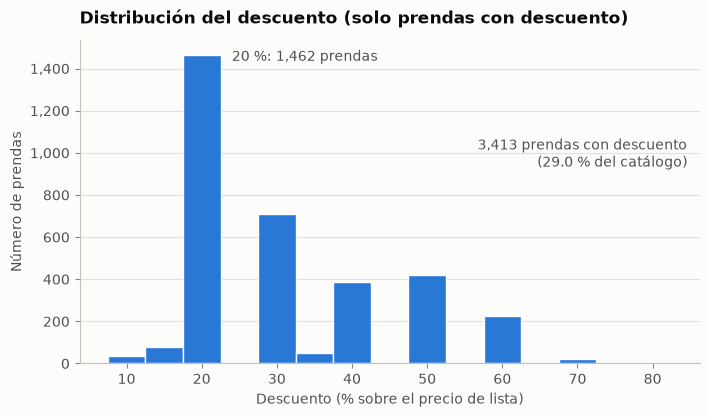

In [8]:
con_desc = df.loc[df["descuento_pct"] > 0, "descuento_pct"] * 100
print(f"Prendas con descuento: {len(con_desc):,} ({len(con_desc) / len(df):.1%})")
print(con_desc.describe(percentiles=[0.25, 0.5, 0.75]).round(1).to_dict())
moda = con_desc.round().mode()[0]
n_moda = int((con_desc.round() == moda).sum())
print(f"Descuento más frecuente: {moda:.0f} % ({n_moda:,} prendas, {n_moda / len(con_desc):.1%} de las que tienen descuento)")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(con_desc, bins=np.arange(7.5, 87.5, 5), color=AZUL, edgecolor=SUPERFICIE, linewidth=1)
ax.text(moda + 4, ax.get_ylim()[1] * 0.97, f"{moda:.0f} %: {n_moda:,} prendas", va="top", color=TINTA2)
ax.text(0.98, 0.7, f"{len(con_desc):,} prendas con descuento\n({len(con_desc) / len(df) * 100:.1f} % del catálogo)",
        transform=ax.transAxes, ha="right", va="top", color=TINTA2)
ax.set_title("Distribución del descuento (solo prendas con descuento)")
ax.set_xlabel("Descuento (% sobre el precio de lista)")
ax.set_ylabel("Número de prendas")
ax.set_xticks(range(10, 90, 10))
ax.yaxis.set_major_formatter(miles)
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_descuento.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** el 29.0 % de las prendas (3,413) tiene descuento; entre ellas la mediana es 30 % (P25 20 %, P75 40 %, máximo 82 %). El 20 % es el más frecuente: 1,462 prendas, el 42.8 % de las rebajadas.

## 8. Disponibilidad por sección

Disponible en total: 64.9% (7,650 de 11,786) | no disponible: 4,136
{'mujer': 64.2, 'hombre': 58.9, 'bebe': 59.4, 'nina': 77.8, 'nino': 77.6, 'unisex': 99.2}


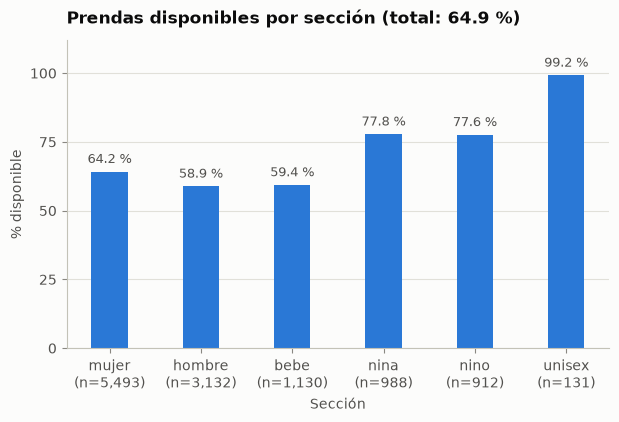

In [9]:
disp = df.groupby("seccion")["disponible"].mean().reindex(por_seccion.index) * 100
disp_total = df["disponible"].mean() * 100
print(f"Disponible en total: {disp_total:.1f}% ({df['disponible'].sum():,} de {len(df):,}) | no disponible: {(~df['disponible']).sum():,}")
print(disp.round(1).to_dict())

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar([f"{s}\n(n={por_seccion[s]:,})" for s in disp.index], disp.values, width=0.4, color=AZUL)
ax.bar_label(barras, labels=[f"{v:.1f} %" for v in disp.values], padding=4, color=TINTA2, fontsize=9)
ax.set_title(f"Prendas disponibles por sección (total: {disp_total:.1f} %)")
ax.set_xlabel("Sección")
ax.set_ylabel("% disponible")
ax.set_ylim(0, 112)
ax.set_yticks(range(0, 101, 25))
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_disponibilidad.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** solo el 64.9 % de las prendas está disponible (4,136 no lo están). Hombre (58.9 %) y bebé (59.4 %) son las secciones más bajas, niña (77.8 %) y niño (77.6 %) las más altas; unisex llega a 99.2 % pero con solo 131 prendas.

## 9. Texto para embeddings (Fase 2)

{'count': 11786.0, 'mean': 72.9, 'std': 36.7, 'min': 1.0, '10%': 35.0, '50%': 67.0, '90%': 123.0, '99%': 191.1, 'max': 455.0}
Vacías o con menos de 5 palabras: 9 (0.08%) | vacías: 0
Filas cuya descripción se repite en otra fila: 4,615 (39.2%) | descripciones distintas: 8,655
Textos repetidos: 1,484 | compartidos por productos distintos (no solo colores): 1,056
Más de 220 palabras (fuera del gráfico): 37


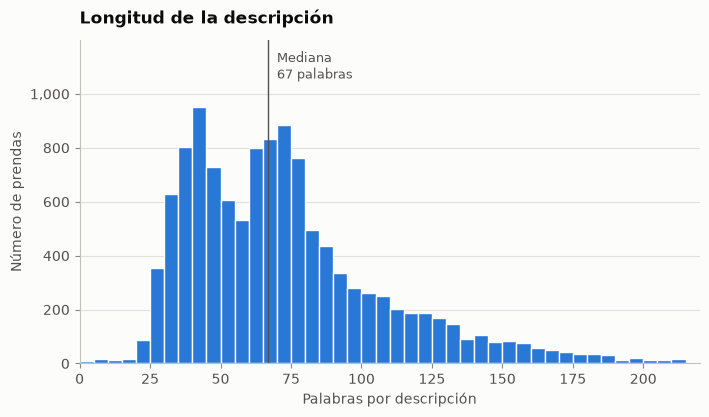

[1 palabras] Sandalias Women Secret café para mujer -> SANDALIA
[1 palabras] Panti Accente estampada para mujer -> PANTY
[3 palabras] Llavero de niña -> LLAVERO DE NIÑA


In [10]:
df["n_palabras"] = df["descripcion"].fillna("").str.split().str.len()
cortas = df["n_palabras"] < 5  # incluye las vacías (0 palabras)
repetida = df["descripcion"].duplicated(keep=False)
print(df["n_palabras"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1).to_dict())
print(f"Vacías o con menos de 5 palabras: {cortas.sum()} ({cortas.mean():.2%}) | vacías: {(df['n_palabras'] == 0).sum()}")
print(f"Filas cuya descripción se repite en otra fila: {repetida.sum():,} ({repetida.mean():.1%}) | descripciones distintas: {df['descripcion'].nunique():,}")
por_texto = df[repetida].groupby("descripcion")["product_id"].nunique()
print(f"Textos repetidos: {len(por_texto):,} | compartidos por productos distintos (no solo colores): {(por_texto > 1).sum():,}")
print(f"Más de 220 palabras (fuera del gráfico): {(df['n_palabras'] > 220).sum()}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(df["n_palabras"], bins=np.arange(0, 465, 5), color=AZUL, edgecolor=SUPERFICIE, linewidth=1)
ax.set_xlim(0, 220)
mediana_pal = df["n_palabras"].median()
ax.set_ylim(0, ax.get_ylim()[1] * 1.2)  # aire arriba para la etiqueta
ax.axvline(mediana_pal, color=TINTA2, linewidth=1)
ax.text(mediana_pal + 3, ax.get_ylim()[1] * 0.97, f"Mediana\n{mediana_pal:.0f} palabras", color=TINTA2, fontsize=9, va="top")
ax.set_title("Longitud de la descripción")
ax.set_xlabel("Palabras por descripción")
ax.set_ylabel("Número de prendas")
ax.yaxis.set_major_formatter(miles)
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_descripcion.png", dpi=150, bbox_inches="tight")
plt.show()

# 3 ejemplos de las descripciones más cortas (distintas entre sí)
for _, f in df.drop_duplicates("descripcion").nsmallest(3, "n_palabras").iterrows():
    print(f"[{f['n_palabras']} palabras] {f['nombre']} -> {f['descripcion']}")

**Hallazgo:** mediana de 67 palabras (P10 35, P90 123), ninguna vacía y solo 9 (0.08 %) con menos de 5 palabras, que son apenas el tipo en mayúsculas ("SANDALIA", "PANTY", "LLAVERO DE NIÑA"). Lo que sí pesa: el 39.2 % de las filas (4,615) comparte descripción con otra; hay solo 8,655 textos distintos.

## Hallazgos para el modelado

- **Desbalance por sección.** Mujer y hombre son el 73.2 % del catálogo; unisex (131) y las tres secciones infantiles (912 a 1,130 cada una) son pocas. El split es temporal (train = meses anteriores, val = penúltima semana, test = última semana), no estratificado por `seccion`; hay que reportar recall@12 por sección; el mapeo de `seccion` con `index_group_name` de H&M será más débil en unisex y en niña/niño/bebé.
- **Cola larga en `tipo_prenda` y color.** El top 20 cubre el 83.9 % del catálogo y 13 de 55 tipos tienen menos de 30 prendas (sudadera 23, bota 12, abrigo 2). Si H&M vende mucho de esos tipos, en Siman habrá muy pocos candidatos y unas pocas prendas absorberán todas las compras mapeadas; algo parecido pasa con el color, donde el 21.4 % (multicolor, metálico, otro) no tiene un color único que emparejar.
- **Marcas concentradas.** Sfera es el 15.7 % del catálogo y el top 10 el 43.1 %; 85 de 215 marcas tienen menos de 10 prendas. La línea base y la torre de ítems tenderán a favorecer a Sfera y las marcas raras serán cold-start; además la marca no tiene contraparte en H&M, así que solo sirve como atributo del catálogo.
- **Precio asimétrico y con descuentos.** Mediana Q219 frente a máximo Q3,449 y 29.0 % de prendas con descuento (mediana 30 %): conviene usar log(precio) y el precio de lista aparte. Como la mediana cambia por sección (Q127 niña, Q279 hombre), el precio de H&M no se puede convertir directo a Q; mejor mapear por percentil dentro de cada sección.
- **Disponibilidad.** El 35.1 % del catálogo (4,136 prendas) no está disponible, y en hombre y bebé ronda el 41 %. Hay que decidir si el recomendador las excluye y evaluar recall@12 con y sin ellas.
- **Calidad del texto para embeddings.** Las descripciones son largas y no hay vacías (mediana 67 palabras), pero el 39.2 % de las filas comparte texto con otra y las más cortas solo dicen el tipo en mayúsculas. Los embeddings de texto serán casi idénticos entre muchas prendas, así que conviene armar el texto con nombre + categoría + color + descripción.